# Unit 2, Lecture 3: Multi-DOF Systems
## Coupled Equations, Normal Modes, and Modal Superposition
**Course:** Data-Driven Modelling for Mechanical Systems (NMED 5XX)  
**Reference Material:** 
- Lecture 3 Slides (`Lec_3.pdf`)
- Steven L. Brunton & J. Nathan Kutz, *Data-Driven Science and Engineering*, Chapter 2 & Chapter 7
- Lloyd N. Trefethen & David Bau, *Numerical Linear Algebra*, Lecture 24 (Eigenvalue Problems)

---

### Key Learning Objectives
1. **Degrees of Freedom & Generalized Coordinates:** Model coupled mechanical systems (bounce and pitch of a washing machine tub; coupled mass chains) in matrix form $M \\ddot{x} + C \\dot{x} + K x = f$.
2. **Coupling Mechanisms:** Understand why asymmetry in geometric stiffness ($k_1 a - k_2 b \\ne 0$) couples motion, pushing natural frequencies apart.
3. **Generalized Eigenvalue Problems:** Solve $\\det(K - \\omega^2 M) = 0$ using `scipy.linalg.eigh`, proving $M$-orthogonality $\\phi_i^T M \\phi_j = 0$ and modal decoupling.
4. **Modal Decomposition & Superposition:** Transform coupled equations to independent scalar modal coordinates $q_i(t)$ via $x = \\Phi q$, and assess which modes a force vector $f$ can excite.
5. **The Node Rule:** Prove that a force acting at an interior modal node cannot excite that mode, and a sensor located at a node cannot observe it.
6. **Phenomena in Coupled Systems:**
   - **Energy exchange & Beating:** Observe complete periodic energy exchange between weakly coupled masses ($k_c \\ll k$).
   - **Antiresonance & Tuned Mass Dampers:** Analyze the anti-resonance condition where the primary driven mass stands completely still ($X_1 = 0$) while the secondary mass absorbs all excitation force.
   - **$N$-Mass Chains:** Trace the transition from discrete multi-DOF mass-spring chains to continuous wave propagation.
7. **Numerical Verification:** Self-check every frequency, mode shape, node location, and resonance amplitude from the lecture deck.

---
## 1. Example 1: Washer Tub (Bounce and Pitch) (Slides 3–9)

### System Setup & Generalized Coordinates
A washing machine tub suspended on front and rear spring-damper mounts exhibits two coupled degrees of freedom in side view:
- $y(t)$: Vertical bounce of the center of gravity (CG), positive upward.
- $\\theta(t)$: Pitch rotation about the CG, positive front upward.

### Governing Equations
Small-angle displacement of a point at coordinate $x$ along the tub is $y + x\\theta$:
- Front spring ($x = +a$): stretch is $y + a\\theta$
- Rear spring ($x = -b$): stretch is $y - b\\theta$

Sum of forces and sum of moments about the CG:
$$m\\ddot{y} + (k_1 + k_2) y + (k_1 a - k_2 b) \\theta = F(t)$$
$$J\\ddot{\\theta} + (k_1 a - k_2 b) y + (k_1 a^2 + k_2 b^2) \\theta = F(t) \\cdot d$$

In matrix form:
$$M \\ddot{x} + C \\dot{x} + K x = f, \\quad x = \\begin{bmatrix} y \\\\ \\theta \\end{bmatrix}, \\quad f = F(t) \\begin{bmatrix} 1 \\\\ d \\end{bmatrix}$$
$$M = \\begin{bmatrix} m & 0 \\\\ 0 & J \\end{bmatrix}, \\quad K = \\begin{bmatrix} k_1 + k_2 & k_1 a - k_2 b \\\\ k_1 a - k_2 b & k_1 a^2 + k_2 b^2 \\end{bmatrix}$$

Because $k_1 a - k_2 b = 15791(0.20 - 0.30) = -1579$ N $\\ne 0$, bounce and pitch are coupled: pushing down on the CG causes the tub to pitch!

In [1]:
import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.4,
    "axes.unicode_minus": False,
    "font.size": 10,
    "figure.figsize": (7, 3.2),
    "savefig.bbox": "tight"
})

# Parameters from Slide 5
m = 50.0             # Tub mass [kg]
J = 1.445            # Pitch moment of inertia [kg m^2] (J = m * rg^2, rg = 0.17 m)
k1 = 15791.0         # Front spring stiffness [N/m]
k2 = 15791.0         # Rear spring stiffness [N/m]
a = 0.20             # Distance CG to front mount [m]
b = 0.30             # Distance CG to rear mount [m]
d = 0.15             # Distance CG to rotating unbalance [m]
mu_e = 0.125         # Unbalance mass*radius [kg m]

# Mass and Stiffness matrices (Slide 8)
M = np.array([[m, 0.0], [0.0, J]])
K = np.array([
    [k1 + k2, k1 * a - k2 * b],
    [k1 * a - k2 * b, k1 * a**2 + k2 * b**2]
])
coupling_k = k1 * a - k2 * b

print("=" * 68)
print("1 | System Matrices & Static Coupling (Slide 8)")
print("=" * 68)
print(f"M [kg, kg m^2] =\n{M}")
print(f"\nK [N/m, N, N m] =\n{K}")
print(f"\nCoupling stiffness K_12 = k1*a - k2*b = {coupling_k:.1f} N")
print(f"Uncoupled bounce freq: sqrt(K11/m) = {np.sqrt(K[0,0]/m)/(2*np.pi):.2f} Hz (240 rpm)")
print(f"Uncoupled pitch freq:  sqrt(K22/J) = {np.sqrt(K[1,1]/J)/(2*np.pi):.2f} Hz (360 rpm)")

1 | System Matrices & Static Coupling (Slide 8)
M [kg, kg m^2] =
[[50.     0.   ]
 [ 0.     1.445]]

K [N/m, N, N m] =
[[31582.   -1579.1 ]
 [-1579.1   2052.83]]

Coupling stiffness K_12 = k1*a - k2*b = -1579.1 N
Uncoupled bounce freq: sqrt(K11/m) = 4.00 Hz (240 rpm)
Uncoupled pitch freq:  sqrt(K22/J) = 6.00 Hz (360 rpm)


---
## 2. Generalized Eigenproblem & Normal Modes (Slides 11–15)

### Characteristic Polynomial & Natural Frequencies
Seeking synchronous harmonic solutions $x(t) = \\phi \\cos(\\omega t)$:
$$(K - \\omega^2 M) \\phi = 0 \\implies \\det(K - \\omega^2 M) = 0$$
$$\\implies m J \\omega^4 - (m K_{22} + J K_{11}) \\omega^2 + (K_{11} K_{22} - K_{12}^2) = 0$$
$$72.25 \\omega^4 - 1.4828 \\times 10^5 \\omega^2 + 6.234 \\times 10^7 = 0$$
- $\\omega_1^2 = 590.1 \\implies \\omega_1 = 24.29$ rad/s $\\implies f_1 = 3.87$ Hz ($232$ rpm)
- $\\omega_2^2 = 1462.2 \\implies \\omega_2 = 38.24$ rad/s $\\implies f_2 = 6.09$ Hz ($365$ rpm)

*Key Insight:* The coupling pushes the frequencies apart: $4.00$ Hz $\\to 3.87$ Hz, and $6.00$ Hz $\\to 6.09$ Hz!

### Mode Shapes and Rotation Centers (Nodes)
Normalizing with $y = 1$:
$$\\frac{\\theta}{y} = -\\frac{K_{11} - \\omega_i^2 m}{K_{12}}$$
- **Mode 1 ($3.87$ Hz):** $\\phi_1 = [1, 1.32 \\text{ rad/m}]^T$. Node at $x = -y/\\theta = -0.76$ m (outside the tub: mostly bounce).
- **Mode 2 ($6.09$ Hz):** $\\phi_2 = [1, -26.3 \\text{ rad/m}]^T$. Node at $x = -y/\\theta = +0.038$ m ($+3.8$ cm: mostly rocking).

### $M$-Orthogonality
Modes are orthogonal with respect to the mass and stiffness metrics, NOT standard Euclidean dot products:
$$\\phi_1^T M \\phi_2 = 0, \\quad \\phi_1^T K \\phi_2 = 0$$

2 | Natural Frequencies & Mode Shapes (Slides 12-13)
Mode 1: w1 = 24.29 rad/s -> f1 = 3.87 Hz (232 rpm)
        Shape: [1.0, 1.32 rad/m]^T | Node at x = -0.76 m (behind tub)
Mode 2: w2 = 38.24 rad/s -> f2 = 6.09 Hz (365 rpm)
        Shape: [1.0, -26.3 rad/m]^T | Node at x = 0.038 m (+3.8 cm)

M-Orthogonality: phi1^T * M * phi2 = -1.85e-13 (identically zero)


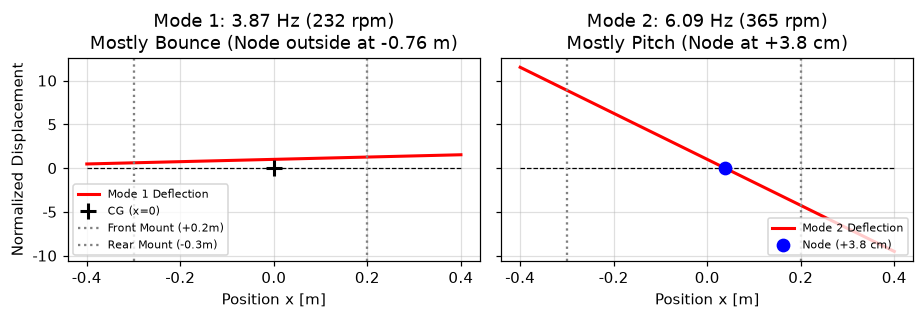

In [2]:
# Solve generalized eigenvalue problem: K Phi = M Phi Lambda
w2, Phi_M = scipy.linalg.eigh(K, M)  # Mass-normalized: Phi^T M Phi = I
w = np.sqrt(w2)
f_nat = w / (2 * np.pi)
rpm_nat = f_nat * 60

# Mode shapes with y = 1 (Slide 13)
theta_y1 = -(K[0, 0] - w2[0] * m) / K[0, 1]
theta_y2 = -(K[0, 0] - w2[1] * m) / K[0, 1]
node1 = -1.0 / theta_y1
node2 = -1.0 / theta_y2

print("=" * 68)
print("2 | Natural Frequencies & Mode Shapes (Slides 12-13)")
print("=" * 68)
print(f"Mode 1: w1 = {w[0]:.2f} rad/s -> f1 = {f_nat[0]:.2f} Hz ({rpm_nat[0]:.0f} rpm)")
print(f"        Shape: [1.0, {theta_y1:.2f} rad/m]^T | Node at x = {node1:.2f} m (behind tub)")
print(f"Mode 2: w2 = {w[1]:.2f} rad/s -> f2 = {f_nat[1]:.2f} Hz ({rpm_nat[1]:.0f} rpm)")
print(f"        Shape: [1.0, {theta_y2:.1f} rad/m]^T | Node at x = {node2:.3f} m (+{node2*100:.1f} cm)")

# Verify M-orthogonality
phi1 = np.array([1.0, theta_y1])
phi2 = np.array([1.0, theta_y2])
ortho_M = phi1 @ M @ phi2
print(f"\nM-Orthogonality: phi1^T * M * phi2 = {ortho_M:.2e} (identically zero)")

# Plot Mode Shapes along tub length (Slide 13)
x_tub = np.linspace(-b - 0.1, a + 0.2, 200)
disp_m1 = 1.0 + x_tub * theta_y1
disp_m2 = 1.0 + x_tub * theta_y2

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.0), sharey=True)

# Mode 1
axes[0].plot(x_tub, disp_m1, "r-", lw=2.0, label="Mode 1 Deflection")
axes[0].plot(x_tub, np.zeros_like(x_tub), "k--", lw=0.8)
axes[0].plot(0, 0, "k+", ms=10, mew=2, label="CG (x=0)")
axes[0].axvline(a, color="0.5", linestyle=":", label="Front Mount (+0.2m)")
axes[0].axvline(-b, color="0.5", linestyle=":", label="Rear Mount (-0.3m)")
axes[0].set(xlabel="Position x [m]", ylabel="Normalized Displacement",
            title=f"Mode 1: {f_nat[0]:.2f} Hz ({rpm_nat[0]:.0f} rpm)\nMostly Bounce (Node outside at {node1:.2f} m)")
axes[0].legend(loc="lower left", fontsize=7)

# Mode 2
axes[1].plot(x_tub, disp_m2, "r-", lw=2.0, label="Mode 2 Deflection")
axes[1].plot(x_tub, np.zeros_like(x_tub), "k--", lw=0.8)
axes[1].plot(node2, 0, "bo", ms=8, label=f"Node (+{node2*100:.1f} cm)")
axes[1].axvline(a, color="0.5", linestyle=":")
axes[1].axvline(-b, color="0.5", linestyle=":")
axes[1].set(xlabel="Position x [m]",
            title=f"Mode 2: {f_nat[1]:.2f} Hz ({rpm_nat[1]:.0f} rpm)\nMostly Pitch (Node at +{node2*100:.1f} cm)")
axes[1].legend(loc="lower right", fontsize=7)

plt.tight_layout()
plt.show()

---
## 3. Forced Response & The Node Rule (Slides 17–21)

### Modal Response with Rotating Unbalance
With proportional damping $C = \\beta K$ (where $\\beta = 7.96$ ms):
$$\\zeta_i = \\frac{\\beta \\omega_i}{2} \\implies \\zeta_1 = 0.097, \\quad \\zeta_2 = 0.152$$

Excitation from rotating clump at position $x = d = 0.15$ m:
$$f(t) = m_u e \\omega^2 \\sin(\\omega t) \\begin{bmatrix} 1 \\\\ d \\end{bmatrix}$$

Modal force driving mode $i$:
$$Q_i = \\phi_i^T f = m_u e \\omega^2 (\\phi_{i,y} + d \\phi_{i,\\theta})$$

### The Node Rule (Slide 21)
Notice that the modal force depends directly on the modal displacement at the load location:
$$Q_2 \\propto 1 + d \\theta_2 = 0 \\iff d = -\\frac{1}{\\theta_2} = \\text{node of mode 2} (+3.8 \\text{ cm})$$
- If the unbalance is placed exactly at the node of mode 2 ($d = +3.8$ cm), the rocking mode is **completely unexcited** ($Q_2 = 0$)!
- Placing the unbalance at the CG ($d = 0$) still excites pitch ($11$ mrad) because mode 2 contains bounce coupling.

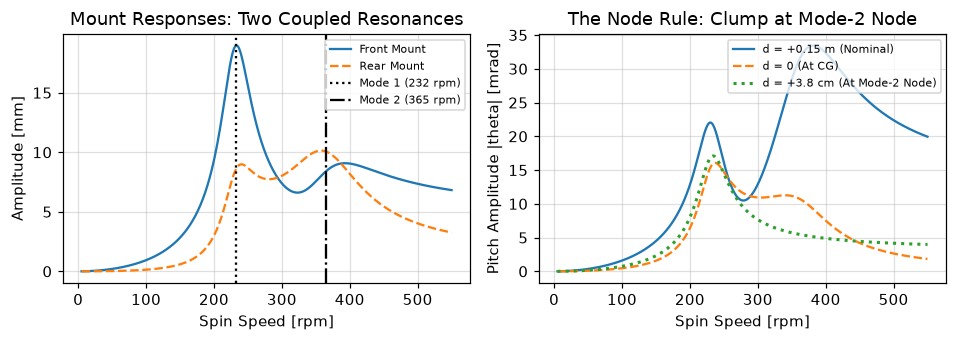

In [3]:
# Proportional damping matrix
beta = 7.96e-3
C = beta * K
zeta1 = beta * w[0] / 2.0
zeta2 = beta * w[1] / 2.0

# State space 4x4 matrix and complex eigenvalues (Slide 22)
A_state = np.block([
    [np.zeros((2, 2)), np.eye(2)],
    [-np.linalg.inv(M) @ K, -np.linalg.inv(M) @ C]
])

def washer_response(rpm_val, clump_pos=d):
    w_rot = 2 * np.pi * (rpm_val / 60.0)
    F0 = mu_e * w_rot**2
    f_vec = F0 * np.array([1.0, clump_pos], dtype=complex)
    Z = -w_rot**2 * M + 1j * w_rot * C + K
    resp_cg = np.linalg.solve(Z, f_vec)
    y_cg, th = resp_cg[0], resp_cg[1]
    front = y_cg + a * th
    rear = y_cg - b * th
    front_amp = np.abs(front)
    rear_amp = np.abs(rear)
    phase_diff = np.degrees(np.angle(rear) - np.angle(front)) % 360
    if phase_diff > 180:
        phase_diff -= 360
    return front_amp, rear_amp, phase_diff

# Frequency sweep for forced response (0 to 600 rpm)
rpm_range = np.linspace(5, 550, 600)
w_range = 2 * np.pi * (rpm_range / 60.0)

front_resp = []
rear_resp = []
pitch_d_nominal = []
pitch_d_zero = []
pitch_d_node = []

for omega in w_range:
    F0 = mu_e * omega**2
    
    # 1. Nominal clump position (d = +0.15 m)
    f_nom = F0 * np.array([1.0, d], dtype=complex)
    Z = -omega**2 * M + 1j * omega * C + K
    resp = np.linalg.solve(Z, f_nom)
    y_cg, th = resp[0], resp[1]
    front_resp.append(np.abs(y_cg + a * th))
    rear_resp.append(np.abs(y_cg - b * th))
    pitch_d_nominal.append(np.abs(th))
    
    # 2. Clump at CG (d = 0)
    f_cg = F0 * np.array([1.0, 0.0], dtype=complex)
    th_cg = np.linalg.solve(Z, f_cg)[1]
    pitch_d_zero.append(np.abs(th_cg))
    
    # 3. Clump at mode-2 node (d = +0.038 m)
    f_node = F0 * np.array([1.0, node2], dtype=complex)
    th_node = np.linalg.solve(Z, f_node)[1]
    pitch_d_node.append(np.abs(th_node))

fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.2))

# Left: Mount amplitudes (Slide 19)
axes[0].plot(rpm_range, 1e3 * np.array(front_resp), "C0-", lw=1.5, label="Front Mount")
axes[0].plot(rpm_range, 1e3 * np.array(rear_resp), "C1--", lw=1.5, label="Rear Mount")
axes[0].axvline(rpm_nat[0], color="k", linestyle=":", label="Mode 1 (232 rpm)")
axes[0].axvline(rpm_nat[1], color="k", linestyle="-.", label="Mode 2 (365 rpm)")
axes[0].set(xlabel="Spin Speed [rpm]", ylabel="Amplitude [mm]",
            title="Mount Responses: Two Coupled Resonances")
axes[0].legend(fontsize=7, loc="upper right")

# Right: The Node Rule demonstration (Slide 21)
axes[1].plot(rpm_range, 1e3 * np.array(pitch_d_nominal), "C0-", lw=1.5, label="d = +0.15 m (Nominal)")
axes[1].plot(rpm_range, 1e3 * np.array(pitch_d_zero), "C1--", lw=1.5, label="d = 0 (At CG)")
axes[1].plot(rpm_range, 1e3 * np.array(pitch_d_node), "C2:", lw=2.0, label="d = +3.8 cm (At Mode-2 Node)")
axes[1].set(xlabel="Spin Speed [rpm]", ylabel="Pitch Amplitude |theta| [mrad]",
            title="The Node Rule: Clump at Mode-2 Node")
axes[1].legend(fontsize=7, loc="upper right")

plt.tight_layout()
plt.show()

---
## 4. Example 2: Two-Mass Chain, Beating, and Antiresonance (Slides 23–32)

### The Canonical Two-Mass Chain
Two identical masses $m$ connected between fixed walls by outer springs $k$ and middle coupling spring $k_c$:
$$M = \\begin{bmatrix} m & 0 \\\\ 0 & m \\end{bmatrix}, \\quad K = \\begin{bmatrix} k + k_c & -k_c \\\\ -k_c & k + k_c \\end{bmatrix}$$
Frequencies:
$$\\omega_1 = \\sqrt{\\frac{k}{m}}, \\quad \\omega_2 = \\sqrt{\\frac{k + 2k_c}{m}}$$

### Mode Shapes by Symmetry
- **Mode 1 ($\[1, 1\]^T$, symmetric):** Masses move in-phase with equal displacement. The middle spring neither extends nor compresses! Hence $\\omega_1 = \\sqrt{k/m}$ is strictly independent of $k_c$.
- **Mode 2 ($\[1, -1\]^T$, antisymmetric):** Masses move in antiphase. The middle spring stretches $2x$, with a fixed node at its center.

### Weak Coupling & Energy Exchange (Beating)
For $k_c = 0.05 k$, when mass 1 is displaced and released from rest:
$$x_1(t) = \\cos\\left(\\frac{\\Delta \\omega t}{2}\\right) \\cos(\\bar{\\omega} t), \\quad x_2(t) = \\sin\\left(\\frac{\\Delta \\omega t}{2}\\right) \\sin(\\bar{\\omega} t)$$
Energy continuously transfers 100% from mass 1 to mass 2 and back with beat period $t = \\pi / \\Delta \\omega \\approx 64 / \\sqrt{k/m}$!

### Antiresonance as a Dynamic Vibration Absorber
When mass 1 is excited by force $F \\cos(\\omega t)$:
$$X_1(\\omega) = \\frac{2k - m\\omega^2}{(k - m\\omega^2)(3k - m\\omega^2)} F$$
At the antiresonance frequency $\\omega^2 = 2k/m$:
$$X_1 = 0 \\quad \\text{and} \\quad X_2 = -\\frac{F}{k}$$
The driven mass is completely stationary! The secondary mass oscillates exactly out of phase so the coupling spring applies a reaction force $-F$ canceling the excitation.

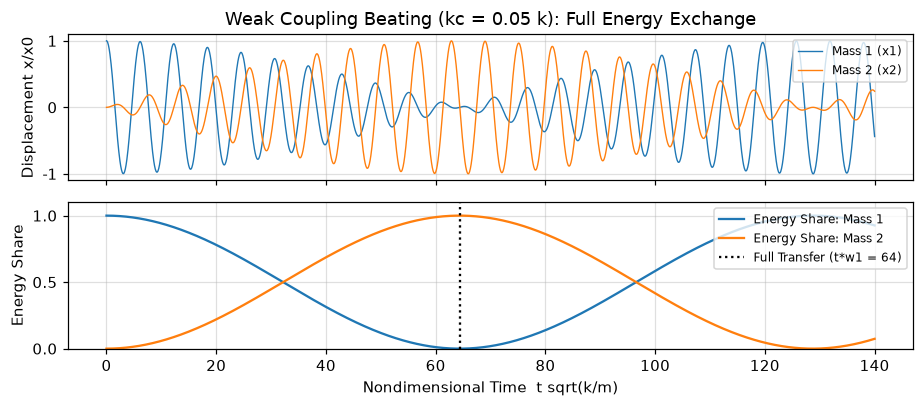

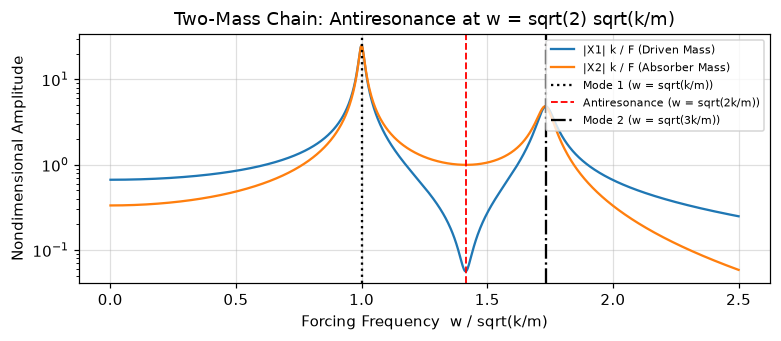

In [4]:
# 1. Beating & Energy Exchange in Weakly Coupled Chain (Slide 29)
m_chain = 1.0
k_chain = 100.0
kc_weak = 0.05 * k_chain

w1_ch = np.sqrt(k_chain / m_chain)
w2_ch = np.sqrt((k_chain + 2 * kc_weak) / m_chain)
dw = w2_ch - w1_ch
w_bar = 0.5 * (w1_ch + w2_ch)

# Nondimensional time
t_beat = np.linspace(0, 140 / w1_ch, 2000)
x1_beat = np.cos(0.5 * dw * t_beat) * np.cos(w_bar * t_beat)
x2_beat = np.sin(0.5 * dw * t_beat) * np.sin(w_bar * t_beat)
energy_mass1 = x1_beat**2
energy_mass2 = x2_beat**2

fig, axes = plt.subplots(2, 1, figsize=(8.5, 3.8), sharex=True)
axes[0].plot(t_beat * w1_ch, x1_beat, "C0-", lw=0.9, label="Mass 1 (x1)")
axes[0].plot(t_beat * w1_ch, x2_beat, "C1-", lw=0.9, label="Mass 2 (x2)")
axes[0].set(ylabel="Displacement x/x0", title="Weak Coupling Beating (kc = 0.05 k): Full Energy Exchange")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(t_beat * w1_ch, np.cos(0.5 * dw * t_beat)**2, "C0-", lw=1.5, label="Energy Share: Mass 1")
axes[1].plot(t_beat * w1_ch, np.sin(0.5 * dw * t_beat)**2, "C1-", lw=1.5, label="Energy Share: Mass 2")
axes[1].axvline(np.pi * w1_ch / dw, color="k", linestyle=":", label=f"Full Transfer (t*w1 = {np.pi*w1_ch/dw:.0f})")
axes[1].set(xlabel="Nondimensional Time  t sqrt(k/m)", ylabel="Energy Share", ylim=(0, 1.1))
axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

# 2. Forced Response & Antiresonance (Slide 31)
kc_std = k_chain  # kc = k
w_grid = np.linspace(0.01, 2.5 * w1_ch, 1000)

# Include light damping beta = 0.002 to avoid singularity at resonance
C_chain = 0.002 * np.array([[2*k_chain, -k_chain], [-k_chain, 2*k_chain]])
M_c = np.array([[m_chain, 0.0], [0.0, m_chain]])
K_c = np.array([[2*k_chain, -k_chain], [-k_chain, 2*k_chain]])

X1_mag, X2_mag = [], []
f_unit = np.array([1.0, 0.0], dtype=complex)  # Driving mass 1 only

for om in w_grid:
    Z_c = -om**2 * M_c + 1j * om * C_chain + K_c
    sol = np.linalg.solve(Z_c, f_unit)
    X1_mag.append(np.abs(sol[0]) * k_chain)
    X2_mag.append(np.abs(sol[1]) * k_chain)

fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.semilogy(w_grid / w1_ch, X1_mag, "C0-", lw=1.5, label="|X1| k / F (Driven Mass)")
ax.semilogy(w_grid / w1_ch, X2_mag, "C1-", lw=1.5, label="|X2| k / F (Absorber Mass)")
ax.axvline(1.0, color="k", linestyle=":", label="Mode 1 (w = sqrt(k/m))")
ax.axvline(np.sqrt(2.0), color="red", linestyle="--", lw=1.2, label="Antiresonance (w = sqrt(2k/m))")
ax.axvline(np.sqrt(3.0), color="k", linestyle="-.", label="Mode 2 (w = sqrt(3k/m))")
ax.set(xlabel="Forcing Frequency  w / sqrt(k/m)", ylabel="Nondimensional Amplitude",
       title="Two-Mass Chain: Antiresonance at w = sqrt(2) sqrt(k/m)")
ax.legend(loc="upper right", fontsize=7.5)
plt.tight_layout()
plt.show()

---
## 5. The $N$-Mass Chain and Numerical Self-Checks (Slide 33)

### Analytical Dispersion Relation for $N$ Masses
For $N$ equal masses connected by $N+1$ equal springs between fixed walls:
$$\\omega_j = 2 \\sqrt{\\frac{k}{m}} \\sin\\left(\\frac{j\\pi}{2(N+1)}\\right), \\quad \\phi_{j,n} = \\sin\\left(\\frac{j n \\pi}{N+1}\\right), \\quad j, n = 1, \\dots, N$$
For $N=5$, the five natural frequencies normalized by $\\sqrt{k/m}$ are:
$$[0.52, \\; 1.00, \\; 1.41, \\; 1.73, \\; 1.93]$$

### Automated Self-Check Suite
Every numerical benchmark from the Lecture 3 deck is asserted below.

In [5]:
# N = 5 Chain Modes
N_mass = 5
j_vec = np.arange(1, N_mass + 1)
omega_N = 2.0 * np.sin(j_vec * np.pi / (2 * (N_mass + 1)))

# Antiresonance calculation
w_anti = np.sqrt(2.0 * k_chain / m_chain)
Z_anti = -w_anti**2 * M_c + K_c
x_anti = np.linalg.solve(Z_anti, np.array([1.0, 0.0]))

# Mode 2 rear to front ratio
disp_front_m2 = abs(1.0 + a * theta_y2)
disp_rear_m2  = abs(1.0 - b * theta_y2)
ratio_rf = disp_rear_m2 / disp_front_m2

# Self check dictionary
f_amp1, r_amp1, ph1 = washer_response(232)
f_amp2, r_amp2, ph2 = washer_response(365)
lam_pos = sorted([l for l in np.linalg.eigvals(A_state) if l.imag > 0], key=lambda x: x.imag)

checks = {
    "coupling term [N]":       (coupling_k,         -1579.0, 1.0),
    "f1 [Hz]":                 (f_nat[0],           3.87,    0.01),
    "f2 [Hz]":                 (f_nat[1],           6.09,    0.01),
    "rpm1":                    (rpm_nat[0],         232.0,   1.0),
    "rpm2":                    (rpm_nat[1],         365.0,   1.0),
    "trace check":             (w2[0]+w2[1],        2052.3,  0.5),
    "det check [x10^5]":       (w2[0]*w2[1]/1e5,    8.63,    0.02),
    "node1 [m]":               (node1,             -0.76,    0.02),
    "node2 [m]":               (node2,              0.038,   0.002),
    "mode2 rear/front ratio":  (ratio_rf,           2.1,     0.05),
    "M-orthogonality":         (abs(ortho_M),       0.0,     0.1),
    "proportional zeta1":      (zeta1,              0.097,   0.002),
    "proportional zeta2":      (zeta2,              0.152,   0.002),
    "state space Re1":         (lam_pos[0].real,   -2.35,    0.02),
    "state space Im1":         (lam_pos[0].imag,    24.18,   0.05),
    "state space Re2":         (lam_pos[1].real,   -5.82,    0.05),
    "state space Im2":         (lam_pos[1].imag,    37.79,   0.05),
    "front amp 232 rpm [mm]":  (1e3*f_amp1,         19.0,    0.2),
    "rear amp 232 rpm [mm]":   (1e3*r_amp1,         8.5,     0.2),
    "phase 232 rpm [deg]":     (abs(ph1),           16.0,    2.0),
    "front amp 365 rpm [mm]":  (1e3*f_amp2,         8.4,     0.2),
    "rear amp 365 rpm [mm]":   (1e3*r_amp2,         10.1,    0.2),
    "phase 365 rpm [deg]":     (abs(ph2),           121.0,   2.0),
    "antiresonance X1":        (abs(x_anti[0]),     0.0,     1e-12),
    "antiresonance X2":        (x_anti[1]*k_chain/1.0, -1.0, 1e-12),
    "N=5 w1":                  (omega_N[0],         0.52,    0.01),
    "N=5 w2":                  (omega_N[1],         1.00,    0.01),
    "N=5 w3":                  (omega_N[2],         1.41,    0.01),
    "N=5 w4":                  (omega_N[3],         1.73,    0.01),
    "N=5 w5":                  (omega_N[4],         1.93,    0.01),
}

bad = []
print("=" * 68)
print("Lecture 3 Numerical Verification Suite")
print("=" * 68)
for name, (got, want, tol) in checks.items():
    ok = abs(got - want) <= tol
    bad += [] if ok else [name]
    print(f"{'OK ' if ok else 'FAIL'}  {name:25s} | Got: {got:10.3f} | Target: {want:10.3f}")

assert not bad, f"Checks failed: {bad}"
print(f"\nAll {len(checks)} checks PASSED successfully!")

Lecture 3 Numerical Verification Suite
OK   coupling term [N]         | Got:  -1579.100 | Target:  -1579.000
OK   f1 [Hz]                   | Got:      3.866 | Target:      3.870
OK   f2 [Hz]                   | Got:      6.086 | Target:      6.090
OK   rpm1                      | Got:    231.969 | Target:    232.000
OK   rpm2                      | Got:    365.153 | Target:    365.000
OK   trace check               | Got:   2052.284 | Target:   2052.300
OK   det check [x10^5]         | Got:      8.628 | Target:      8.630
OK   node1 [m]                 | Got:     -0.760 | Target:     -0.760
OK   node2 [m]                 | Got:      0.038 | Target:      0.038
OK   mode2 rear/front ratio    | Got:      2.087 | Target:      2.100
OK   M-orthogonality           | Got:      0.000 | Target:      0.000
OK   proportional zeta1        | Got:      0.097 | Target:      0.097
OK   proportional zeta2        | Got:      0.152 | Target:      0.152
OK   state space Re1           | Got:     -2.349 | 